data/raw/source_a_synthetic/warehouse_detection_dataset/yolo/images/train/warehouse_010839.png


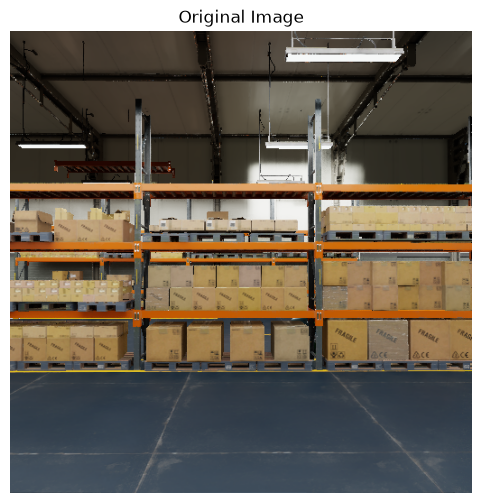

In [ ]:
import os 
import random 
import matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms.v2 as transforms


images_dir = 'data/raw/source_a_synthetic/warehouse_detection_dataset/yolo/images/train'



all_images  = os.listdir(images_dir)   # list if all names of images in yolo train dataset 
sample_image_path = os.path.join(images_dir , random.choice(all_images))

print(sample_image_path)

original_img = Image.open(sample_image_path).convert("RGB")
plt.figure(figsize=(6, 6))
plt.imshow(original_img)
plt.title("Original Image")
plt.axis('off')
plt.show()


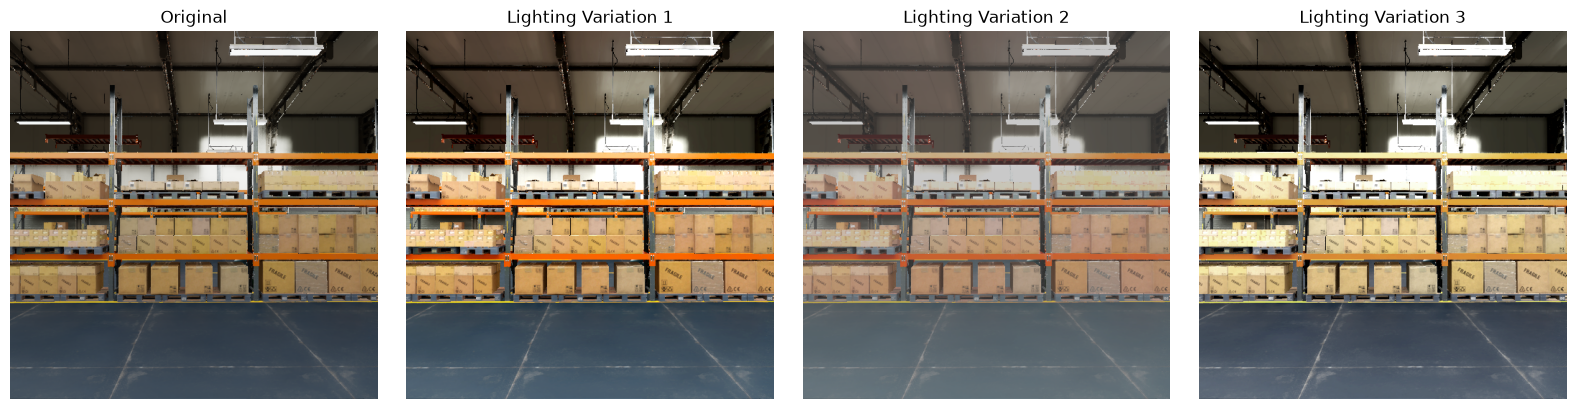

In [20]:
color_jitter = transforms.ColorJitter(
    brightness=0.4,  # Randomly change brightness by up to 40%
    contrast=0.4,    # Randomly change contrast by up to 40%
    saturation=0.4,  # Randomly change saturation by up to 40%
    hue=0.05         # Slight hue shifts (lighting color temperature
)


fig , axes = plt.subplots(1,4, figsize = (16 , 4))
axes[0].imshow(original_img)
axes[0].set_title("Original")
axes[0].axis('off')
for i in range(1, 4):
    jittered_img = color_jitter(original_img)
    axes[i].imshow(jittered_img)
    axes[i].set_title(f"Lighting Variation {i}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()





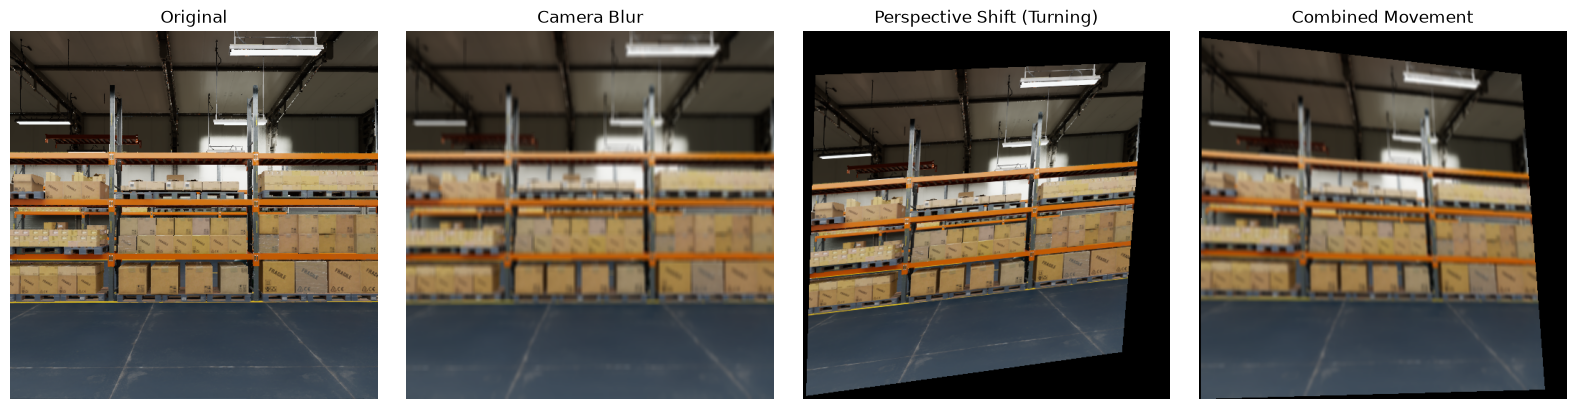

In [ ]:
blur_transform = transforms.GaussianBlur(kernel_size=(5, 9), sigma=(0.1, 5.0))
perspective_transform = transforms.RandomPerspective(distortion_scale = 0.3 , p = 1.0)




# --------------------------------------------------------------------#

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(original_img)
axes[0].set_title("Original")
axes[0].axis('off')
# 1. Just Blur (Moving straight, out of focus)
axes[1].imshow(blur_transform(original_img))
axes[1].set_title("Camera Blur")
axes[1].axis('off')
# 2. Just Perspective (Robot turning a corner)
axes[2].imshow(perspective_transform(original_img))
axes[2].set_title("Perspective Shift (Turning)")
axes[2].axis('off')
# 3. Combined (Fast movement while turning)
combined_transform = transforms.Compose([
    blur_transform,
    perspective_transform
])
axes[3].imshow(combined_transform(original_img))
axes[3].set_title("Combined Movement")
axes[3].axis('off')
plt.tight_layout()
plt.show()


#--------------------------------------------------------------------------#



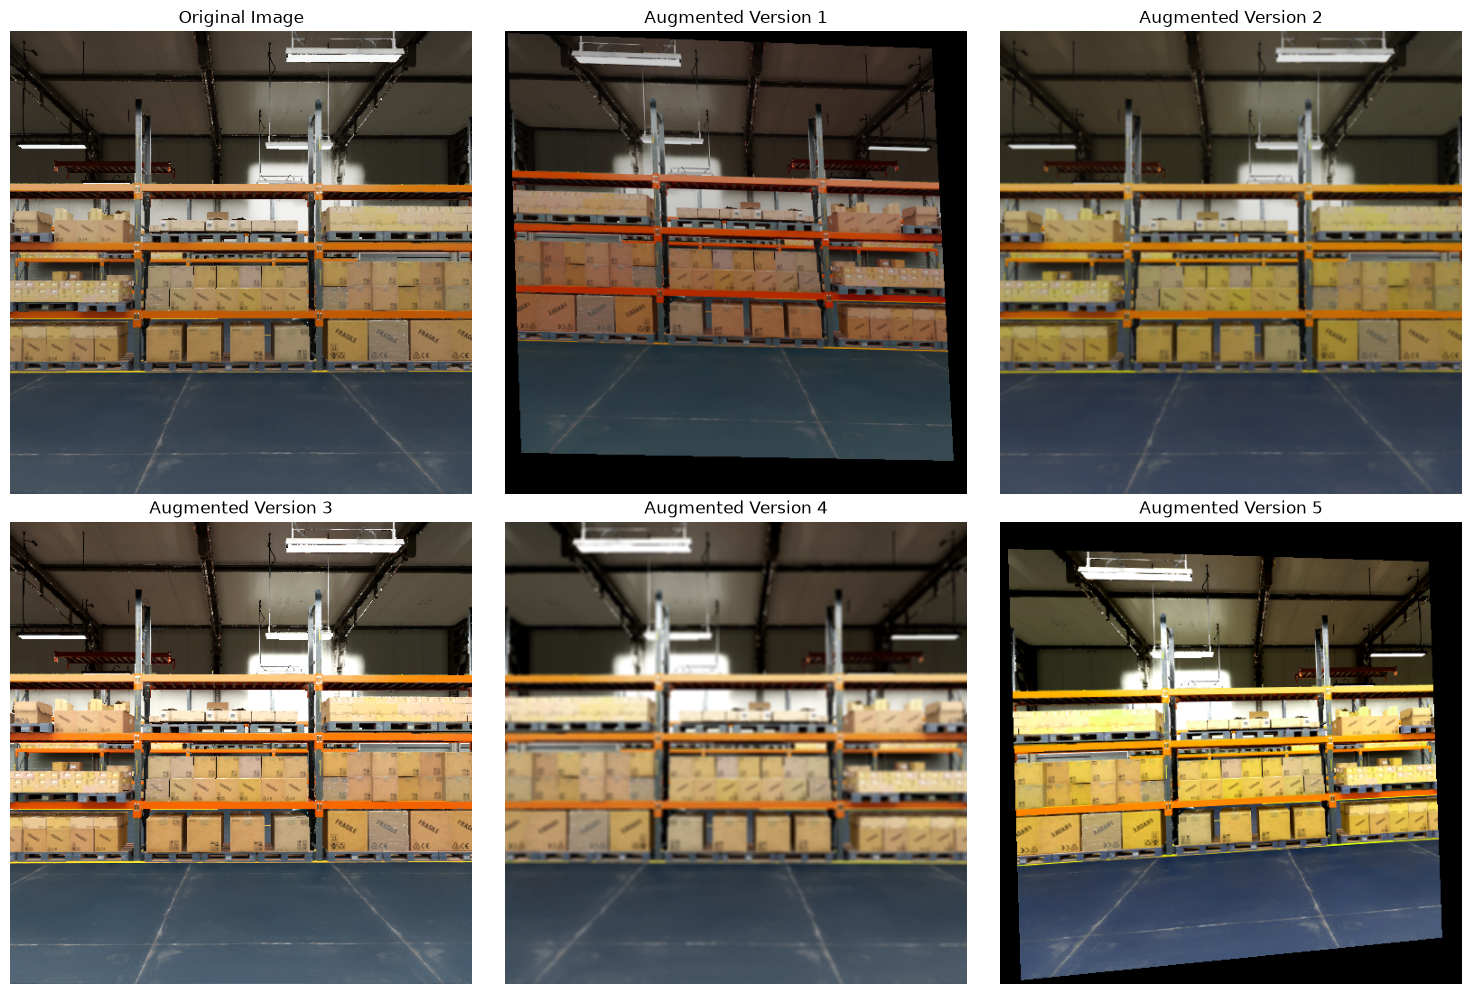

In [22]:
# The final training pipeline
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5), # 50% chance to flip horizontally
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 2.0))], p=0.3), # 30% chance for blur
    transforms.RandomPerspective(distortion_scale=0.2, p=0.2), # 20% chance for perspective shift
])

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

axes[0].imshow(original_img)
axes[0].set_title("Original Image")
axes[0].axis('off')

for i in range(1, 6):
    augmented_img = train_transforms(original_img)
    axes[i].imshow(augmented_img)
    axes[i].set_title(f"Augmented Version {i}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()
